# 03 — DCC-GARCH

> **SYNTHETIC / SIMULATED DATA — NOT REAL MARKET DATA.**

Le DCC utilise exclusivement les résidus standardisés des modèles GARCH univariés. $Q_t=(1-a-b)\bar Q+a z_{t-1}z'_{t-1}+bQ_{t-1}$ puis $R_t=\operatorname{diag}(Q_t)^{-1/2}Q_t\operatorname{diag}(Q_t)^{-1/2}$. La vraisemblance gaussienne quasi-conditionnelle est optimisée sous $a\ge0$, $b\ge0$, $a+b<1$. Une corrélation élevée ne démontre pas une causalité.

SYNTHETIC / SIMULATED DATA — NOT REAL MARKET DATA a= 0.0 b= 0.7322178208981217 a+b= 0.7322178208981217
Dates communes retenues: 1304 du 2021-01-01 00:00:00 au 2025-12-31 00:00:00


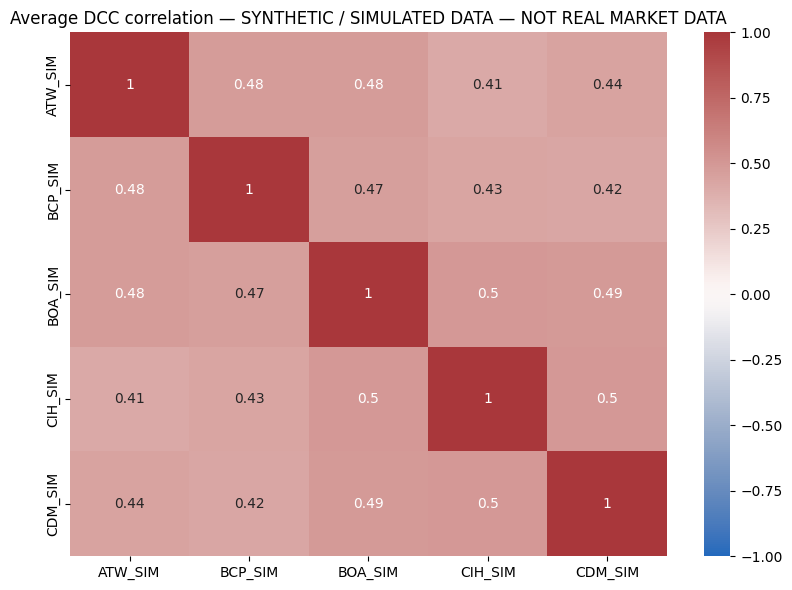

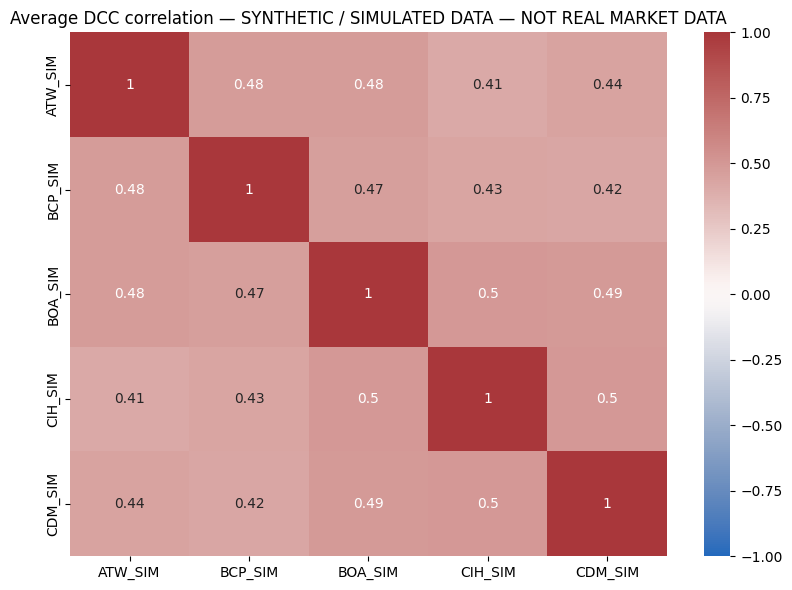

In [1]:
from src.data import load_synthetic_dataset
from src.garch import fit_garch_panel, align_standardized_residuals
from src.dcc_garch import fit_dcc
from src.systemic_risk import correlation_summary
from src.visualization import plot_correlation, plot_series
from src.config import SYNTHETIC_LABEL

_, returns, _, _ = load_synthetic_dataset()
garch = fit_garch_panel(returns)
standardized = align_standardized_residuals(garch)
dcc = fit_dcc(standardized)
print(SYNTHETIC_LABEL, 'a=', dcc.a, 'b=', dcc.b, 'a+b=', dcc.a + dcc.b)
print('Dates communes retenues:', len(standardized), 'du', standardized.index.min(), 'au', standardized.index.max())
display(plot_correlation(dcc.average_correlation))

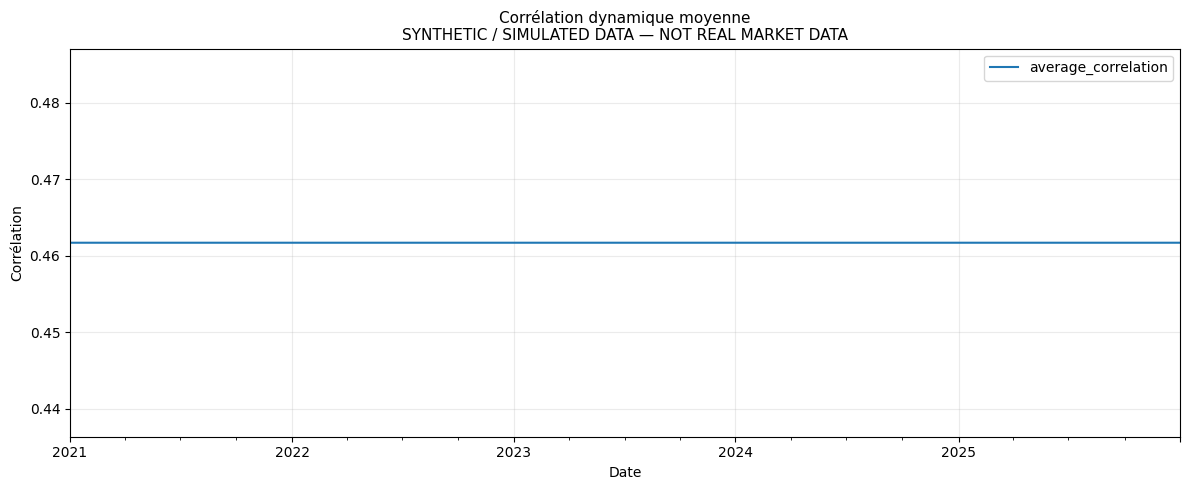

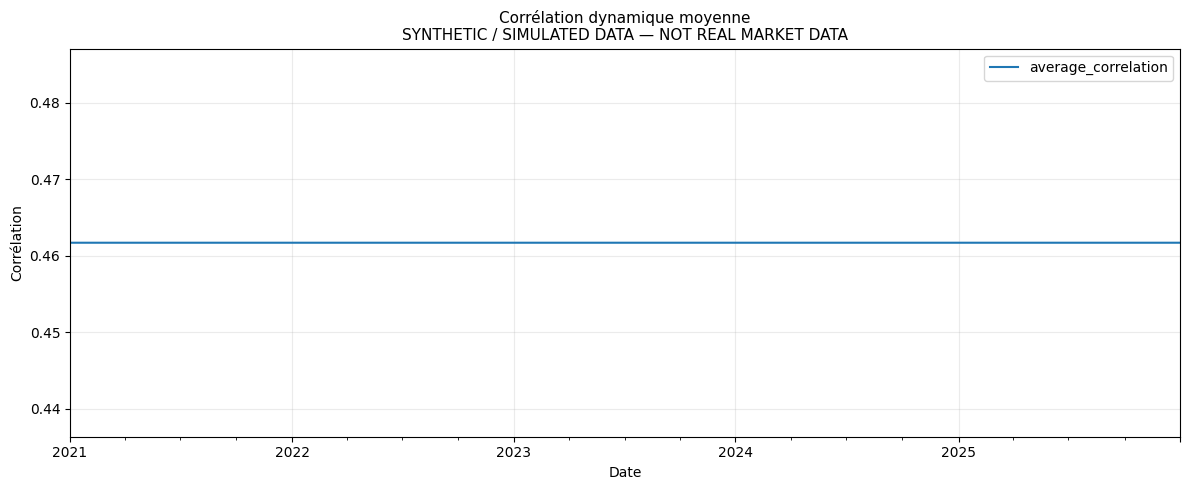

In [2]:
average = correlation_summary(dcc.correlations, dcc.observation_dates, dcc.columns)
display(plot_series(average, 'Corrélation dynamique moyenne', 'Corrélation'))
assert dcc.a >= 0 and dcc.b >= 0 and dcc.a + dcc.b < 1
assert dcc.correlations.shape[0] == len(standardized)
assert dcc.observation_dates.equals(standardized.index)

L'alignement des résidus est une jointure interne sur les dates communes : les observations absentes/non finies sont exclues, jamais remplacées par zéro ni interpolées. Les dates conservées sont celles affichées dans les résultats. L'indice simulé de marché n'est pas intégré comme une sixième banque dans le DCC: les cinq institutions constituent le système étudié. L'indice est un proxy simulé, construit comme moyenne des rendements bancaires.